# Program 2 – Gradient Clipping to Prevent Exploding Gradients

**Objective:** Show the effect of gradient clipping during training.

**Dataset:** IMDB movie-review sentiment classification (25,000 train / 25,000 test reviews, label 0 = negative, 1 = positive)

**Key tasks**
1. Build a small RNN model.
2. Train once **without** clipping and once **with** `clipnorm` (or `clipvalue`) in the optimizer.
3. Plot gradient norms and loss stability.

## Theory (for viva)

**Exploding gradients:** In RNNs, backpropagation through time multiplies many Jacobians (one per time step). If their magnitude is > 1, the gradient grows exponentially → huge weight updates → loss spikes or becomes `NaN`.

**Gradient clipping** limits the gradient before the weight update:

- **Clip by norm (`clipnorm=c`)**: if $\|g\| > c$ then $g \leftarrow g \cdot \dfrac{c}{\|g\|}$. Direction is kept, only length is reduced.
- **Clip by value (`clipvalue=c`)**: every element is clamped to $[-c, c]$. Can change gradient direction.
- **Global norm clipping (`global_clipnorm=c`)**: same as clipnorm but computed over *all* weights together.

**Global gradient norm:** $\|g\| = \sqrt{\sum_i g_i^2}$ over every trainable weight — we record this every step to see explosions.

To make explosions visible we deliberately use a **ReLU RNN** with a **high learning rate** + momentum.

## Step 1 – Import libraries

In [6]:
import keras  # Keras 3 API (runs on TensorFlow backend)
from keras import layers  # Layer classes (Dense, Dropout, Embedding, ...)
import matplotlib.pyplot as plt  # Plotting graphs
import numpy as np  # Numerical arrays
import tensorflow as tf  # TensorFlow (tensors, GradientTape, seeds)

## Step 2 – Load and pad IMDB data

In [7]:
VOCAB_SIZE = 10000     # Keep only the 10,000 most frequent words
MAX_LEN = 100          # Every review is cut/padded to 100 words
BATCH_SIZE = 64        # Mini-batch size

(x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)  # Reviews already encoded as word indices

x_train = keras.utils.pad_sequences(x_train, maxlen=MAX_LEN)   # Pad short / truncate long reviews to MAX_LEN
x_test = keras.utils.pad_sequences(x_test, maxlen=MAX_LEN)     # Same for test set

y_train = y_train.astype("float32")    # Labels as float for binary cross-entropy
y_test = y_test.astype("float32")      # Same for test labels

print("x_train shape:", x_train.shape) # (25000, 100)
print("x_test shape :", x_test.shape)  # (25000, 100)

train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))  # Build a tf.data pipeline from arrays
            .shuffle(10000, seed=42)                                 # Shuffle with buffer 10,000
            .batch(BATCH_SIZE))                                      # Group into batches of 64

x_train shape: (25000, 100)
x_test shape : (25000, 100)


## Step 3 – Build a small RNN model

In [8]:
def build_rnn():                                                  # Returns a new untrained RNN model
    model = keras.Sequential([                                    # Stack layers in order
        keras.Input(shape=(MAX_LEN,)),                            # Input: sequence of 100 word indices
        layers.Embedding(VOCAB_SIZE, 32),                         # Map each word index to a 32-dim vector
        layers.SimpleRNN(64, activation="relu"),                  # RNN with 64 units; ReLU makes explosions likely
        layers.Dense(1, activation="sigmoid"),                    # Output: probability review is positive
    ])
    return model                                                  # Return the model

build_rnn().summary()                                             # Print architecture once

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Step 4 – Custom training loop that records the gradient norm

`model.fit()` does not expose gradients, so we write the loop ourselves with `tf.GradientTape`.
We record the **gradient norm before clipping** (what the network "wanted" to apply) and the loss at every step.

In [9]:
LEARNING_RATE = 0.1    # Deliberately high learning rate to provoke exploding gradients
EPOCHS = 3             # Few epochs are enough to see the difference
CLIP_NORM = 1.0        # Threshold used for clipping


def train_model(clipnorm=None):                                   # clipnorm=None -> no clipping
    tf.random.set_seed(42)                                        # Same initial weights for both runs
    model = build_rnn()                                           # Fresh model
    if clipnorm is None:                                          # Case 1: no clipping
        optimizer = keras.optimizers.SGD(learning_rate=LEARNING_RATE, momentum=0.9)  # Plain SGD + momentum
    else:                                                         # Case 2: with clipping
        optimizer = keras.optimizers.SGD(learning_rate=LEARNING_RATE, momentum=0.9,
                                         clipnorm=clipnorm)       # Optimizer rescales each gradient to norm <= clipnorm
    loss_fn = keras.losses.BinaryCrossentropy()                   # Loss for binary classification

    @tf.function                                                  # Compile step into a fast TF graph
    def train_step(xb, yb):                                       # One gradient update on one batch
        with tf.GradientTape() as tape:                           # Record operations for automatic differentiation
            preds = model(xb, training=True)                      # Forward pass
            loss = loss_fn(yb[:, None], preds)                    # Compute loss (labels reshaped to (batch, 1))
        grads = tape.gradient(loss, model.trainable_variables)    # Backward pass: d(loss)/d(weights)
        grads = [tf.convert_to_tensor(g) for g in grads]          # Convert sparse Embedding grads to dense tensors
        grad_norm = tf.linalg.global_norm(grads)                  # Global L2 norm of all gradients (BEFORE clipping)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))  # Update weights (clipping happens inside here)
        return loss, grad_norm                                    # Return values for logging

    step_losses, step_norms = [], []                              # Lists to collect per-step values
    for epoch in range(EPOCHS):                                   # Loop over epochs
        for xb, yb in train_ds:                                   # Loop over mini-batches
            loss, norm = train_step(xb, yb)                       # Run one training step
            step_losses.append(float(loss))                       # Save loss as Python float
            step_norms.append(float(norm))                        # Save gradient norm as Python float
        print(f"epoch {epoch + 1}: last loss = {step_losses[-1]:.4f}, "
              f"max grad norm this run = {max(step_norms):.2f}")  # Progress report
    return model, np.array(step_losses), np.array(step_norms)     # Return model and logs as arrays

## Step 5 – Train WITHOUT clipping

In [10]:
print("Training WITHOUT gradient clipping")                       # Header
model_noclip, loss_noclip, norm_noclip = train_model(clipnorm=None)  # Run training with no clipping

Training WITHOUT gradient clipping
epoch 1: last loss = nan, max grad norm this run = 1115.42
epoch 2: last loss = nan, max grad norm this run = 1115.42
epoch 3: last loss = nan, max grad norm this run = 1115.42


## Step 6 – Train WITH clipping (`clipnorm=1.0`)

In [11]:
print(f"Training WITH gradient clipping (clipnorm={CLIP_NORM})")  # Header
model_clip, loss_clip, norm_clip = train_model(clipnorm=CLIP_NORM)  # Run training with clipping

Training WITH gradient clipping (clipnorm=1.0)
epoch 1: last loss = 0.5880, max grad norm this run = 2.63
epoch 2: last loss = 0.5795, max grad norm this run = 2226440896512.00
epoch 3: last loss = 0.5355, max grad norm this run = 2226440896512.00


## Step 7 – Plot gradient norms and loss stability

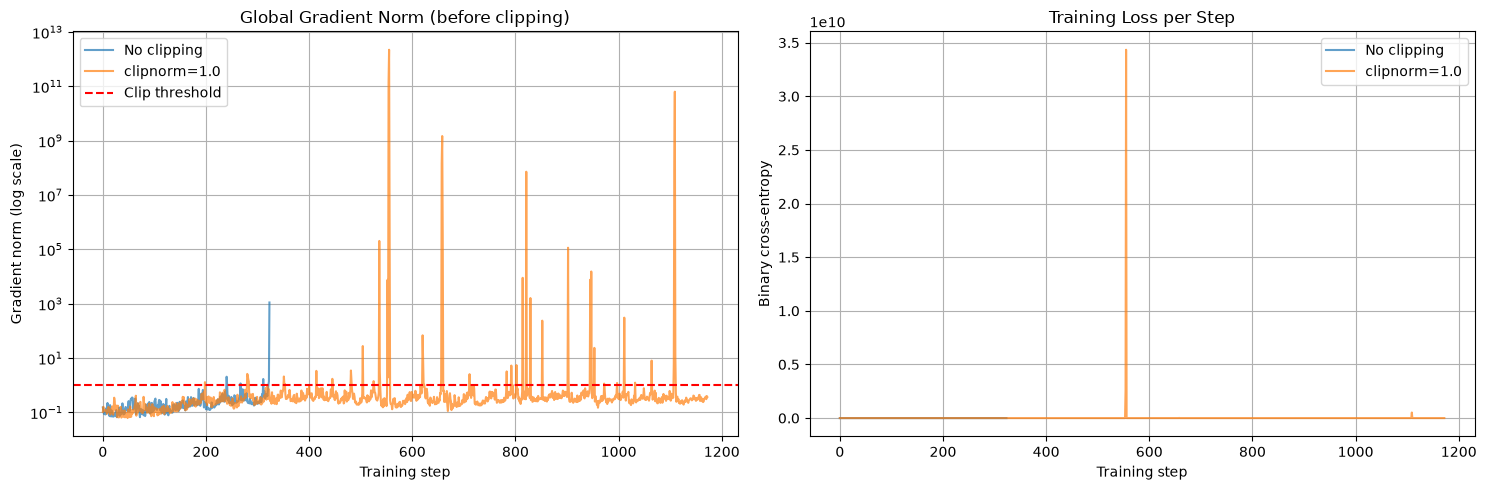

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))                   # Two plots side by side

axes[0].plot(norm_noclip, label="No clipping", alpha=0.7)         # Gradient norm per step without clipping
axes[0].plot(norm_clip, label=f"clipnorm={CLIP_NORM}", alpha=0.7) # Gradient norm per step with clipping
axes[0].axhline(CLIP_NORM, color="red", linestyle="--", label="Clip threshold")  # Horizontal line at threshold
axes[0].set_yscale("log")                                         # Log scale because explosions are huge
axes[0].set_title("Global Gradient Norm (before clipping)")       # Title
axes[0].set_xlabel("Training step")                               # X label
axes[0].set_ylabel("Gradient norm (log scale)")                   # Y label
axes[0].legend()                                                  # Legend
axes[0].grid(True)                                                # Grid

axes[1].plot(loss_noclip, label="No clipping", alpha=0.7)         # Loss per step without clipping
axes[1].plot(loss_clip, label=f"clipnorm={CLIP_NORM}", alpha=0.7) # Loss per step with clipping
axes[1].set_title("Training Loss per Step")                       # Title
axes[1].set_xlabel("Training step")                               # X label
axes[1].set_ylabel("Binary cross-entropy")                        # Y label
axes[1].legend()                                                  # Legend
axes[1].grid(True)                                                # Grid

plt.tight_layout()                                                # Tidy layout
plt.show()                                                        # Show figure

## Step 8 – Compare stability statistics and test accuracy

In [13]:
def stats(name, losses, norms, model):                            # Helper to print a summary for one run
    nan_steps = int(np.sum(~np.isfinite(losses)))                 # Count steps where loss became NaN/inf
    finite = losses[np.isfinite(losses)]                          # Keep only valid loss values
    model.compile(loss="binary_crossentropy", metrics=["accuracy"])  # Compile just to use evaluate()
    _, test_acc = model.evaluate(x_test, y_test, verbose=0)       # Test accuracy
    print(f"{name:<15} max grad norm = {np.nanmax(norms):10.2f} | "
          f"loss std = {np.std(finite):.4f} | NaN steps = {nan_steps} | "
          f"test acc = {test_acc:.4f}")                           # Print summary line

stats("No clipping", loss_noclip, norm_noclip, model_noclip)      # Summary without clipping
stats("With clipnorm", loss_clip, norm_clip, model_clip)          # Summary with clipping

No clipping     max grad norm =    1115.42 | loss std = 0.9347 | NaN steps = 849 | test acc = 0.5000
With clipnorm   max grad norm = 2226440896512.00 | loss std = 1005175390.0930 | NaN steps = 0 | test acc = 0.6373


## Step 9 – Same idea with `model.fit()` (the usual Keras way)

In normal Keras code you do not need a custom loop — just pass `clipnorm` or `clipvalue` to the optimizer.

In [14]:
tf.random.set_seed(42)                                            # Reproducible initial weights
model_fit = build_rnn()                                           # Fresh RNN
model_fit.compile(                                                # Configure training
    optimizer=keras.optimizers.SGD(learning_rate=LEARNING_RATE,   # Same high learning rate
                                   momentum=0.9,                  # Same momentum
                                   clipvalue=0.5),                # Clip EACH gradient element to [-0.5, 0.5]
    loss="binary_crossentropy",                                   # Binary classification loss
    metrics=["accuracy"],                                         # Track accuracy
)
model_fit.fit(x_train, y_train, epochs=2, batch_size=BATCH_SIZE,  # Train 2 epochs
              validation_split=0.2, verbose=2)                    # 20% validation, one line per epoch
print("Test accuracy (clipvalue):", model_fit.evaluate(x_test, y_test, verbose=0)[1])  # Evaluate on test set

Epoch 1/2
313/313 - 3s - 10ms/step - accuracy: 0.5480 - loss: 0.6793 - val_accuracy: 0.6064 - val_loss: 0.6512
Epoch 2/2
313/313 - 4s - 12ms/step - accuracy: 0.5074 - loss: nan - val_accuracy: 0.5062 - val_loss: nan
Test accuracy (clipvalue): 0.5


## Expected observations
- **Without clipping:** gradient norm has large spikes (sometimes 100×–1000× bigger); loss jumps around and may become `NaN`.
- **With clipping:** raw gradients may still spike, but the *applied* update is capped at norm 1.0 → loss curve is smoother and training does not diverge.
- If your run shows no explosion, increase `LEARNING_RATE` (e.g. 0.2) or `MAX_LEN`.

## Viva questions
1. Why are RNNs more prone to exploding gradients? → Gradients are multiplied through many time steps (BPTT).
2. Difference between `clipnorm` and `clipvalue`? → clipnorm rescales whole gradient (keeps direction); clipvalue clamps each element (may change direction).
3. Does clipping solve vanishing gradients? → No. It only caps large gradients. Vanishing is handled by LSTM/GRU, ReLU, good initialization, residual connections.
4. Why did we use a custom training loop? → To access and log gradient norms at every step.